# Stage 8: residual-based fault / underperformance flagging

Results of `python -m src.faults`.

**Design.** A forecast that uses the station's own lagged power adapts to a lasting fault and hides it.
So the detector uses an **expected-power model without own-power inputs** (weather of the same hour, sun
position, calendar, station identity and metadata).

**Score per day and station:**
1. ratio = actual energy / expected energy over the bright hours (irradiance >= 200 W/m2);
2. divide by the station's normal ratio (median in the calibration period) and subtract 1;
3. 3-day rolling mean;
4. subtract the median of all stations on the same day (a weather-sensor error moves every station,
   a fault moves one).

A day is flagged when the score is below **-3 robust standard deviations** of the calibration scores.
Calibration = train + validation (all seasons), with out-of-fold expected power.

**Baseline detector:** the same recipe with a plain performance ratio (energy / irradiance).

**No fault labels exist**, so the detectors are scored on synthetic faults injected into the 2023 test
data, and the flags on unmodified data give an upper limit of the false-alarm rate.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

## 1. The expected-power model
Error of the expected power (no own-power inputs). Train and validation are out-of-fold.

In [2]:
pd.read_csv(TABLES + "08_expected_power_model.csv")

,split,expected_from,n_trees,daytime_rmse_norm,daytime_nmae_pct
0,train,out-of-fold,516,0.0546,3.1678
1,val,out-of-fold,516,0.0476,2.9857
2,test,final model,516,0.0768,4.2975


## 2. Thresholds and flags on unmodified test data
Most stations are almost never flagged; a few are flagged for a large part of 2023.

In [3]:
pd.read_csv(TABLES + "08_false_alarms.csv").round(3).T

,0,1
detector,model,pr
threshold,-0.122,-0.16
stations,43,43
scored_days,11918,11918
flagged_days,1280,1236
flagged_day_share_pct,10.74,10.371
median_station_flagged_day_share_pct,0.345,1.099
stations_with_over_10pct_flagged,13,13
episodes,207,201
episodes_per_station_month,0.528,0.513


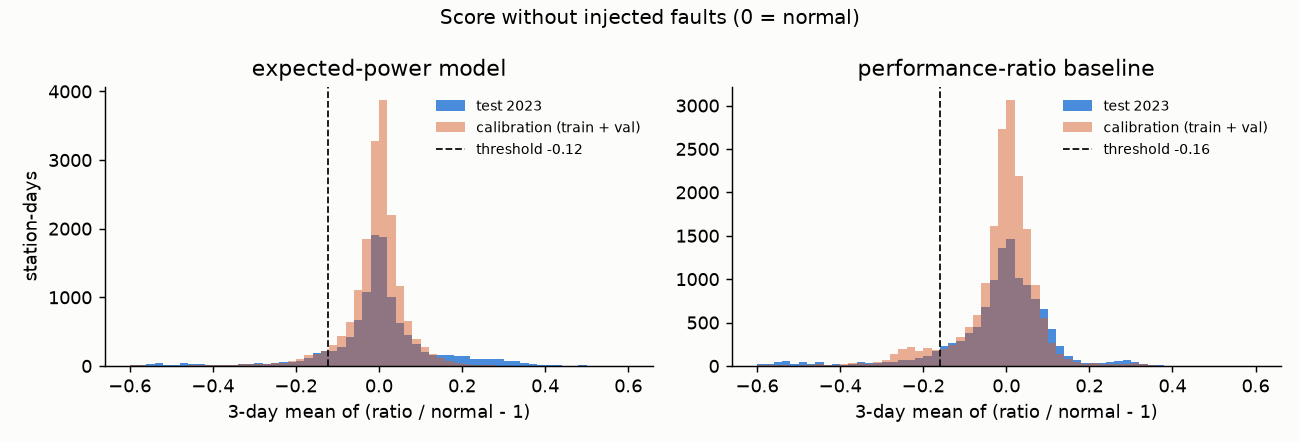

In [4]:
Image(FIGURES + "08_score_spread.png")

## 3. Synthetic faults: recall, precision and delay
Precision assumes one fault per station-year and counts every flagged episode on unmodified data as a false alarm.

In [5]:
det = pd.read_csv(TABLES + "08_fault_detection.csv")
det.pivot(index=["kind", "severity", "duration_days"], columns="detector", values="recall").round(3)

detector                        model     pr
kind    severity duration_days              
drop    0.1      3              0.279  0.246
                 7              0.395  0.321
                 14             0.456  0.363
        0.2      3              0.758  0.721
                 7              0.828  0.763
                 14             0.865  0.851
        0.3      3              0.907  0.916
                 7              0.958  0.967
                 14             0.977  0.986
        0.5      3              0.981  0.977
                 7              0.995  1.000
                 14             0.995  1.000
gradual 0.3      3              0.730  0.656
                 7              0.828  0.837
                 14             0.902  0.926
zero    1.0      3              0.991  0.995
                 7              1.000  1.000
                 14             1.000  1.000

In [6]:
det.pivot(index=["kind", "severity", "duration_days"], columns="detector", values="precision").round(3)

detector                        model     pr
kind    severity duration_days              
drop    0.1      3              0.055  0.050
                 7              0.076  0.064
                 14             0.086  0.072
        0.2      3              0.136  0.134
                 7              0.147  0.140
                 14             0.152  0.154
        0.3      3              0.158  0.164
                 7              0.166  0.172
                 14             0.169  0.174
        0.5      3              0.169  0.173
                 7              0.171  0.176
                 14             0.171  0.176
gradual 0.3      3              0.132  0.123
                 7              0.147  0.152
                 14             0.158  0.165
zero    1.0      3              0.171  0.176
                 7              0.172  0.176
                 14             0.172  0.176

In [7]:
det.pivot(index=["kind", "severity", "duration_days"], columns="detector", values="median_delay_days")

detector                        model   pr
kind    severity duration_days            
drop    0.1      3                1.0  0.0
                 7                2.0  1.0
                 14               2.0  1.5
        0.2      3                1.0  1.0
                 7                1.0  2.0
                 14               1.0  2.0
        0.3      3                1.0  1.0
                 7                1.0  1.0
                 14               1.0  1.0
        0.5      3                0.0  0.0
                 7                0.0  0.0
                 14               0.0  0.0
gradual 0.3      3                2.0  2.0
                 7                3.0  4.0
                 14               6.0  8.0
zero    1.0      3                0.0  0.0
                 7                0.0  0.0
                 14               0.0  0.0

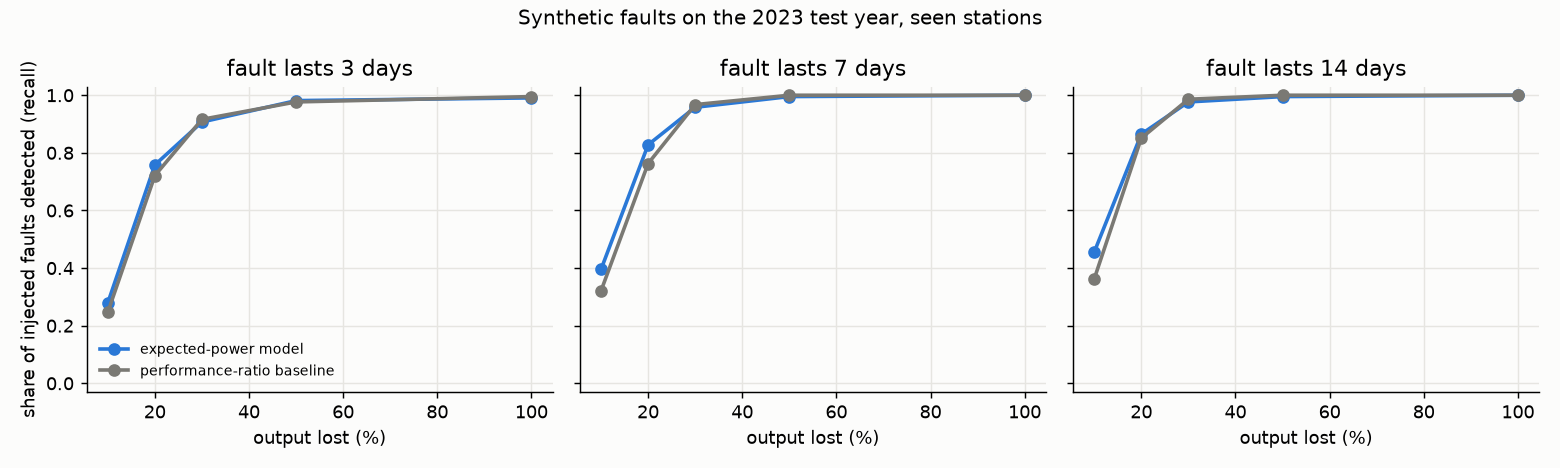

In [8]:
Image(FIGURES + "08_recall_by_severity.png")

## 4. How strict should the threshold be?
A stricter threshold (more sigmas) flags fewer normal days but misses more mild faults.

In [9]:
pd.read_csv(TABLES + "08_threshold_sensitivity.csv").round(3)

,detector,n_sigma,threshold,test_flagged_day_share_pct,recall_drop_10pct_7d,recall_drop_20pct_7d,recall_drop_30pct_7d
0,model,2,-0.081,14.902,0.698,0.902,0.986
1,model,3,-0.122,10.740,0.395,0.828,0.958
2,model,4,-0.163,7.367,0.237,0.744,0.916
3,model,5,-0.204,5.899,0.154,0.502,0.874
4,pr,2,-0.106,16.051,0.554,0.940,0.986
5,pr,3,-0.160,10.371,0.321,0.763,0.967
6,pr,4,-0.213,7.350,0.172,0.498,0.935
7,pr,5,-0.266,5.773,0.107,0.260,0.749


## 5. Why not use the forecast residual?
One injected fault seen by three residuals. The 1-h forecast uses lagged power, which drops with the fault, so its residual stays near 0.

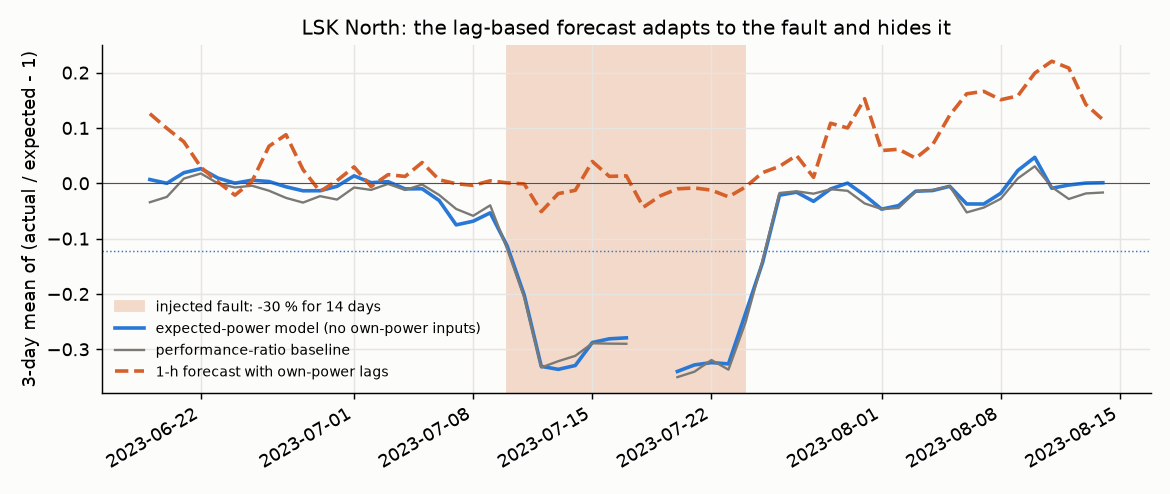

In [10]:
Image(FIGURES + "08_lag_vs_nowcast.png")

In [11]:
pd.read_csv(TABLES + "08_lag_example.csv").round(3).T

,0
station,LSK North
start,2023-07-10
duration_days,14
severity,0.3
mean_score_model,-0.315
mean_score_pr,-0.317
mean_score_lag_forecast,-0.008


## 6. Real flagged periods (candidates, not ground truth)
`has_known_zero_output_hours` = the period overlaps hours flagged in Stage 2 as zero output under strong sun.

In [12]:
real = pd.read_csv(TABLES + "08_flagged_periods.csv")
len(real), real["has_known_zero_output_hours"].sum()

(207, np.int64(13))

In [13]:
real.head(15)

,detector,station,start,end,days,lowest_score,has_known_zero_output_hours
0,model,SQ567 Flexible PV,2023-02-09,2023-02-09,1,-1.1452,True
1,model,Indoor Sports Centre,2023-02-09,2023-02-09,1,-0.9955,False
2,model,Indoor Sports Centre,2023-01-18,2023-02-04,18,-0.9851,False
3,model,SQ567 Flexible PV,2023-03-14,2023-03-19,6,-0.9645,True
4,model,Indoor Sports Centre,2023-01-02,2023-01-08,7,-0.9283,False
5,model,SQ567 Flexible PV,2023-03-24,2023-03-25,2,-0.9178,True
6,model,SQ567 Flexible PV,2023-11-12,2023-12-17,36,-0.9148,False
7,model,SQ1,2023-05-09,2023-05-23,15,-0.9088,True
8,model,SQ567 Flexible PV,2023-10-31,2023-11-07,8,-0.8540,False
9,model,SQ567 Flexible PV,2023-12-24,2023-12-30,7,-0.8475,False


In [14]:
real.groupby("station")["days"].agg(["count", "sum"]).sort_values("sum", ascending=False).head(13)

,count,sum
station,,
SQ567 Flexible PV,22,228
Zone J2,10,188
UG Hall2 RF,19,148
Zone A7,14,90
Wong Check She Research Centre,17,88
SQ Block S,18,82
Zone A1,11,75
SQ Apartment37-48,17,74
UG Hall2 2F,14,69
